# Partie 4 – Métriques de performance par employé

Objectif : analyser les performances des employés de ClassicModels en calculant et visualisant leurs métriques clés pour identifier les meilleurs vendeurs et optimiser la gestion des équipes.

Métriques à analyser :
- **Chiffre d'affaires (CA)** : montant total des ventes réalisées par chaque employé
- **Nombre de clients gérés** : nombre de clients assignés à chaque employé
- **Panier moyen** : montant moyen par commande pour les clients de chaque employé
- **Nombre de commandes** : nombre total de commandes gérées par chaque employé
- **Comparaison des performances** : classement et analyse comparative

Nous utiliserons MySQL comme source de données et Python (pandas, matplotlib, seaborn) pour l'analyse et la visualisation.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.database.connection import fetch_dataframe

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

## Extraction des données de performance des employés

On extrait les données nécessaires pour calculer les métriques de performance de chaque employé.

In [9]:
# Requête pour extraire les métriques de performance par employé
query_employee_performance = """
SELECT
    e.employeeNumber,
    e.lastName,
    e.firstName,
    e.jobTitle,
    e.officeCode,
    o.city AS office_city,
    COUNT(DISTINCT c.customerNumber) AS nb_clients,
    COUNT(DISTINCT o2.orderNumber) AS nb_commandes,
    SUM(od.quantityOrdered * od.priceEach) AS chiffre_affaires,
    AVG(order_totals.montant_commande) AS panier_moyen
FROM employees e
LEFT JOIN customers c ON c.salesRepEmployeeNumber = e.employeeNumber
LEFT JOIN orders o2 ON o2.customerNumber = c.customerNumber AND o2.status = 'Shipped'
LEFT JOIN orderdetails od ON od.orderNumber = o2.orderNumber
LEFT JOIN offices o ON o.officeCode = e.officeCode
LEFT JOIN (
    SELECT 
        orderNumber,
        SUM(quantityOrdered * priceEach) AS montant_commande
    FROM orderdetails
    GROUP BY orderNumber
) AS order_totals ON order_totals.orderNumber = o2.orderNumber
GROUP BY 
    e.employeeNumber,
    e.lastName,
    e.firstName,
    e.jobTitle,
    e.officeCode,
    o.city
ORDER BY chiffre_affaires DESC;
"""

df_employee = fetch_dataframe(query_employee_performance)

# Remplacer les valeurs NULL par 0 pour les employés sans ventes
df_employee = df_employee.fillna(0)

# Créer une colonne nom complet
df_employee['nom_complet'] = df_employee['firstName'] + ' ' + df_employee['lastName']

# Exclure les employés avec des postes de direction/management (pas de ventes directes)
job_titles_to_exclude = [
    'President',
    'VP Sales',
    'VP Marketing',
    'Sales Manager (APAC)',
    'Sale Manager (EMEA)',
    'Sales Manager (NA)'
]

df_employee = df_employee[~df_employee['jobTitle'].isin(job_titles_to_exclude)].copy()

print(f"Nombre d'employés analysés : {len(df_employee)}")
print(f"Employés exclus (postes de direction) : {', '.join(job_titles_to_exclude)}")
print(f"\nPériode : Toutes les commandes 'Shipped'")
df_employee.head()

Nombre d'employés analysés : 17
Employés exclus (postes de direction) : President, VP Sales, VP Marketing, Sales Manager (APAC), Sale Manager (EMEA), Sales Manager (NA)

Période : Toutes les commandes 'Shipped'


C:\Users\bourbia\Desktop\python sql project\src\database\connection.py:51: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn, params=params)


,employeeNumber,lastName,firstName,jobTitle,officeCode,office_city,nb_clients,nb_commandes,chiffre_affaires,panier_moyen,nom_complet
0,1370,Hernandez,Gerard,Sales Rep,4,Paris,7,39,1065035.29,36210.403086,Gerard Hernandez
1,1165,Jennings,Leslie,Sales Rep,1,San Francisco,6,32,1021661.89,40269.062839,Leslie Jennings
2,1401,Castillo,Pamela,Sales Rep,4,Paris,10,27,790297.44,39786.841169,Pamela Castillo
3,1501,Bott,Larry,Sales Rep,7,London,8,21,686653.25,37765.461577,Larry Bott
4,1504,Jones,Barry,Sales Rep,7,London,9,23,637672.65,35666.139343,Barry Jones


## Analyse des métriques de performance

Calcul et analyse des différentes métriques pour chaque employé.

In [10]:
# Statistiques globales
print("=" * 100)
print("STATISTIQUES GLOBALES DES PERFORMANCES EMPLOYÉS")
print("=" * 100)
print(f"\nChiffre d'affaires total : ${df_employee['chiffre_affaires'].sum():,.2f}")
print(f"Chiffre d'affaires moyen par employé : ${df_employee['chiffre_affaires'].mean():,.2f}")
print(f"Chiffre d'affaires médian : ${df_employee['chiffre_affaires'].median():,.2f}")
print(f"\nNombre total de clients gérés : {df_employee['nb_clients'].sum():.0f}")
print(f"Nombre moyen de clients par employé : {df_employee['nb_clients'].mean():.2f}")
print(f"Nombre médian de clients par employé : {df_employee['nb_clients'].median():.2f}")
print(f"\nPanier moyen global : ${df_employee[df_employee['panier_moyen'] > 0]['panier_moyen'].mean():,.2f}")

# Classement des employés
print("\n" + "=" * 100)
print("CLASSEMENT DES EMPLOYÉS PAR CHIFFRE D'AFFAIRES")
print("=" * 100)
top_employees = df_employee[['nom_complet', 'jobTitle', 'office_city', 'chiffre_affaires', 'nb_clients', 'nb_commandes', 'panier_moyen']].copy()
top_employees = top_employees.sort_values('chiffre_affaires', ascending=False)
display(top_employees)

STATISTIQUES GLOBALES DES PERFORMANCES EMPLOYÉS

Chiffre d'affaires total : $8,865,094.64
Chiffre d'affaires moyen par employé : $521,476.16
Chiffre d'affaires médian : $509,385.82

Nombre total de clients gérés : 100
Nombre moyen de clients par employé : 5.88
Nombre médian de clients par employé : 6.00

Panier moyen global : $37,431.27

CLASSEMENT DES EMPLOYÉS PAR CHIFFRE D'AFFAIRES


,nom_complet,jobTitle,office_city,chiffre_affaires,nb_clients,nb_commandes,panier_moyen
0,Gerard Hernandez,Sales Rep,Paris,1065035.29,7,39,36210.403086
1,Leslie Jennings,Sales Rep,San Francisco,1021661.89,6,32,40269.062839
2,Pamela Castillo,Sales Rep,Paris,790297.44,10,27,39786.841169
3,Larry Bott,Sales Rep,London,686653.25,8,21,37765.461577
4,Barry Jones,Sales Rep,London,637672.65,9,23,35666.139343
5,George Vanauf,Sales Rep,NYC,584406.80,8,20,33960.234054
6,Loui Bondur,Sales Rep,Paris,569485.75,6,20,37055.285424
7,Peter Marsh,Sales Rep,Sydney,523860.78,5,17,35728.151807
8,Andy Fixter,Sales Rep,Sydney,509385.82,5,17,35057.838443
9,Foon Yue Tseng,Sales Rep,NYC,488212.67,7,17,35851.774296


## Visualisation des métriques de performance

Graphiques montrant les performances de chaque employé selon différentes métriques.

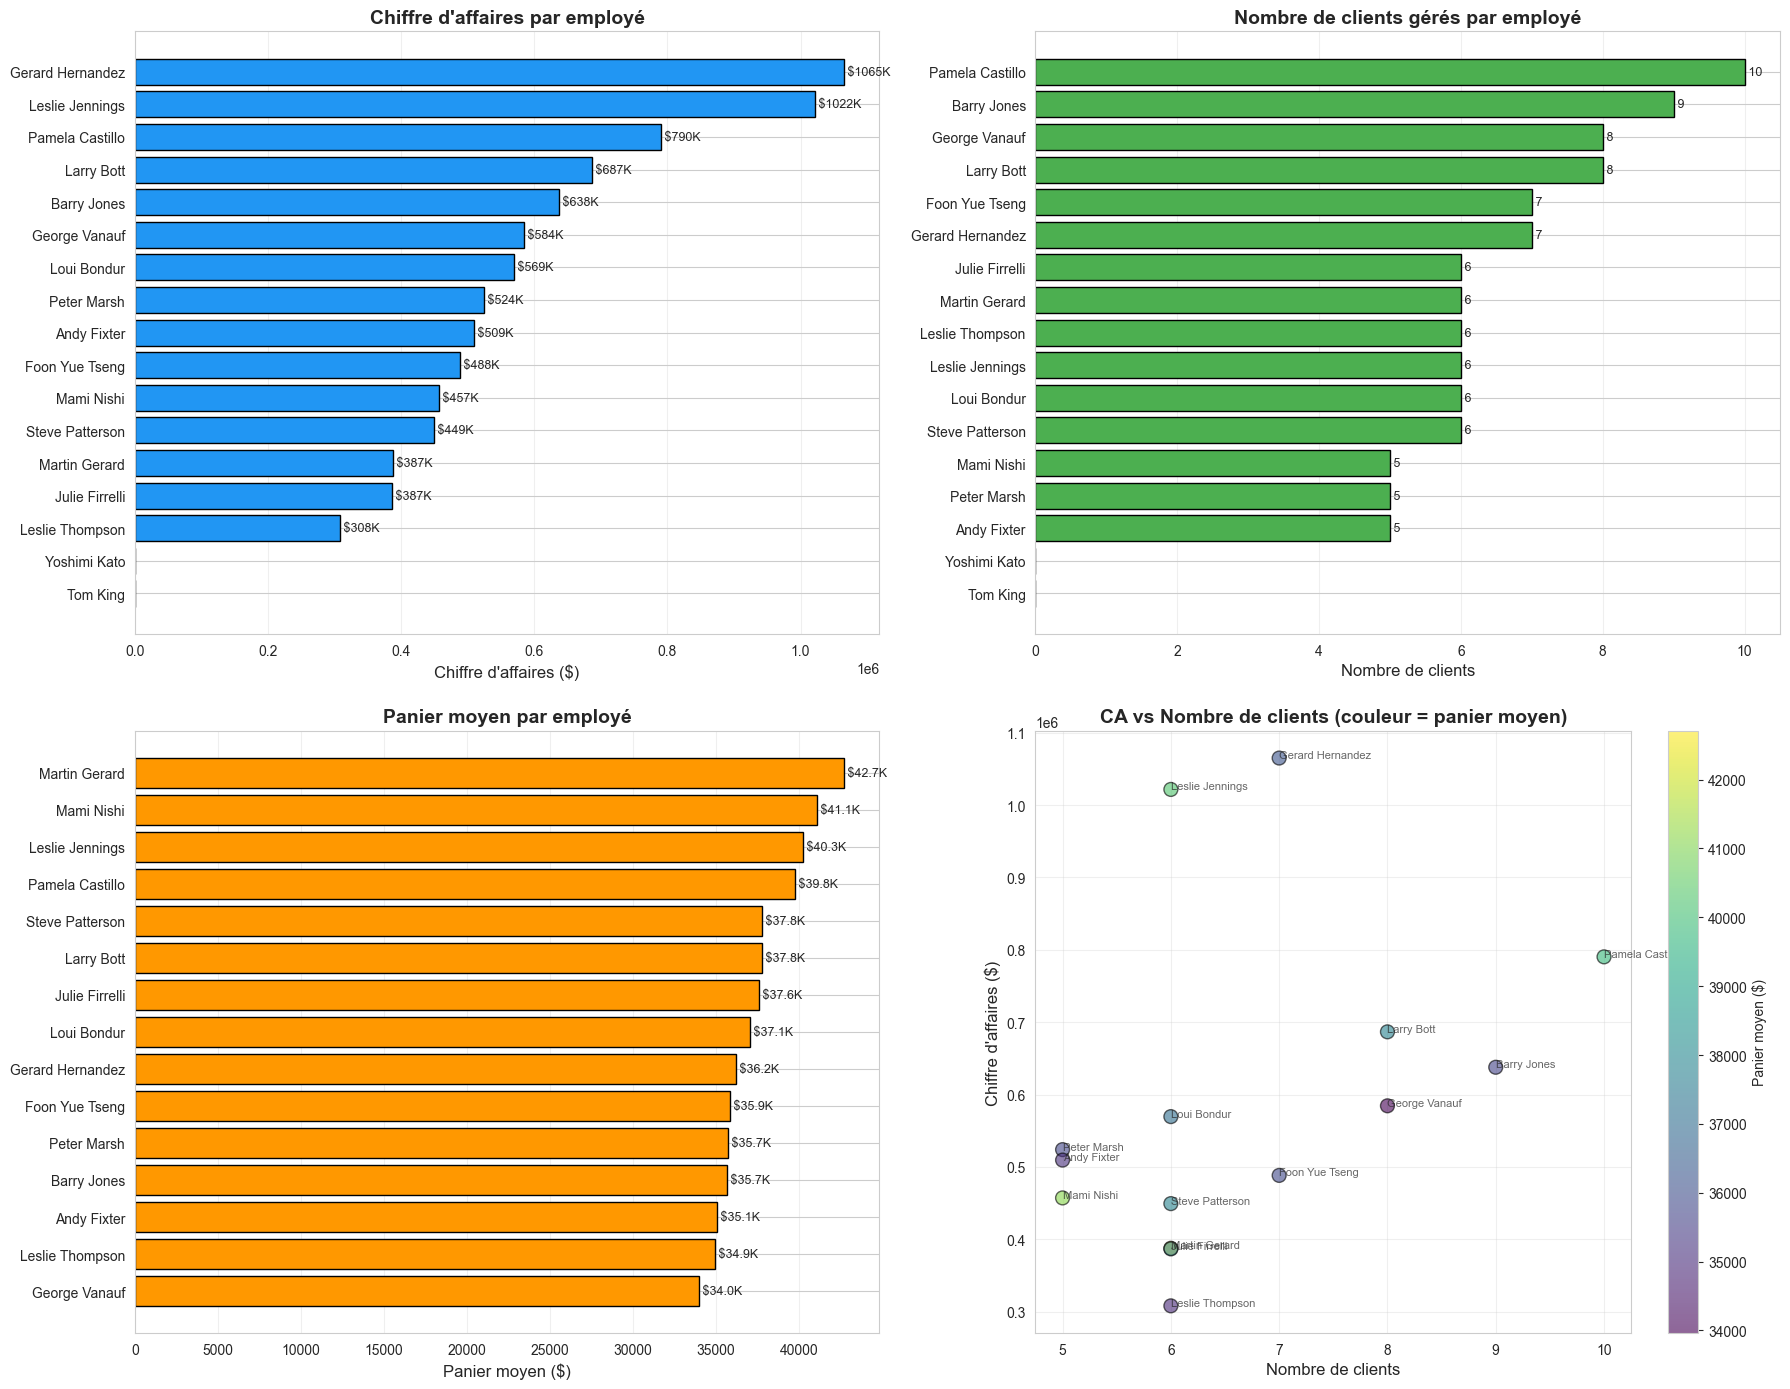

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# 1. Chiffre d'affaires par employé
df_sorted_ca = df_employee.sort_values('chiffre_affaires', ascending=True)
axes[0, 0].barh(range(len(df_sorted_ca)), df_sorted_ca['chiffre_affaires'], color='#2196F3', edgecolor='black')
axes[0, 0].set_yticks(range(len(df_sorted_ca)))
axes[0, 0].set_yticklabels(df_sorted_ca['nom_complet'], fontsize=10)
axes[0, 0].set_xlabel('Chiffre d\'affaires ($)', fontsize=12)
axes[0, 0].set_title('Chiffre d\'affaires par employé', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, axis='x')

# Ajouter les valeurs sur les barres
for i in range(len(df_sorted_ca)):
    row = df_sorted_ca.iloc[i]
    if row['chiffre_affaires'] > 0:
        axes[0, 0].text(row['chiffre_affaires'], i, f" ${row['chiffre_affaires']/1000:.0f}K", 
                       va='center', fontsize=9)

# 2. Nombre de clients gérés par employé
df_sorted_clients = df_employee.sort_values('nb_clients', ascending=True)
axes[0, 1].barh(range(len(df_sorted_clients)), df_sorted_clients['nb_clients'], color='#4CAF50', edgecolor='black')
axes[0, 1].set_yticks(range(len(df_sorted_clients)))
axes[0, 1].set_yticklabels(df_sorted_clients['nom_complet'], fontsize=10)
axes[0, 1].set_xlabel('Nombre de clients', fontsize=12)
axes[0, 1].set_title('Nombre de clients gérés par employé', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='x')

# Ajouter les valeurs sur les barres
for i in range(len(df_sorted_clients)):
    row = df_sorted_clients.iloc[i]
    if row['nb_clients'] > 0:
        axes[0, 1].text(row['nb_clients'], i, f" {int(row['nb_clients'])}", 
                       va='center', fontsize=9)

# 3. Panier moyen par employé (seulement ceux avec des ventes)
df_with_sales = df_employee[df_employee['panier_moyen'] > 0].copy()
df_sorted_panier = df_with_sales.sort_values('panier_moyen', ascending=True)

if len(df_sorted_panier) > 0:
    axes[1, 0].barh(range(len(df_sorted_panier)), df_sorted_panier['panier_moyen'], 
                   color='#FF9800', edgecolor='black')
    axes[1, 0].set_yticks(range(len(df_sorted_panier)))
    axes[1, 0].set_yticklabels(df_sorted_panier['nom_complet'], fontsize=10)
    axes[1, 0].set_xlabel('Panier moyen ($)', fontsize=12)
    axes[1, 0].set_title('Panier moyen par employé', fontsize=14, fontweight='bold')
    axes[1, 0].grid(True, alpha=0.3, axis='x')
    
    # Ajouter les valeurs sur les barres
    for i in range(len(df_sorted_panier)):
        row = df_sorted_panier.iloc[i]
        axes[1, 0].text(row['panier_moyen'], i, f" ${row['panier_moyen']/1000:.1f}K", 
                       va='center', fontsize=9)
else:
    axes[1, 0].text(0.5, 0.5, 'Aucune donnée disponible', ha='center', va='center', 
                   transform=axes[1, 0].transAxes, fontsize=12)
    axes[1, 0].set_title('Panier moyen par employé', fontsize=14, fontweight='bold')

# 4. Scatter plot : CA vs Nombre de clients
df_with_sales_scatter = df_employee[df_employee['chiffre_affaires'] > 0].copy()
if len(df_with_sales_scatter) > 0:
    scatter = axes[1, 1].scatter(df_with_sales_scatter['nb_clients'], 
                                 df_with_sales_scatter['chiffre_affaires'],
                                 s=100, alpha=0.6, c=df_with_sales_scatter['panier_moyen'], 
                                 cmap='viridis', edgecolors='black', linewidth=1)
    
    # Annoter les points avec les noms
    for _, row in df_with_sales_scatter.iterrows():
        axes[1, 1].annotate(row['nom_complet'], 
                           (row['nb_clients'], row['chiffre_affaires']),
                           fontsize=8, alpha=0.7)
    
    axes[1, 1].set_xlabel('Nombre de clients', fontsize=12)
    axes[1, 1].set_ylabel('Chiffre d\'affaires ($)', fontsize=12)
    axes[1, 1].set_title('CA vs Nombre de clients (couleur = panier moyen)', fontsize=14, fontweight='bold')
    axes[1, 1].grid(True, alpha=0.3)
    
    # Ajouter colorbar
    cbar = plt.colorbar(scatter, ax=axes[1, 1])
    cbar.set_label('Panier moyen ($)', fontsize=10)
else:
    axes[1, 1].text(0.5, 0.5, 'Aucune donnée disponible', ha='center', va='center', 
                   transform=axes[1, 1].transAxes, fontsize=12)
    axes[1, 1].set_title('CA vs Nombre de clients', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

## Analyse comparative par bureau

Comparaison des performances des employés par bureau (office).

PERFORMANCES PAR BUREAU


,bureau,CA_total,nb_clients_total,nb_commandes_total,nb_employes,CA_moyen_par_employe
3,Paris,2812295.95,29,98,4,703073.987500
4,San Francisco,1329614.32,12,45,2,664807.160000
1,London,1324325.90,17,44,2,662162.950000
2,NYC,1072619.47,15,37,2,536309.735000
5,Sydney,1033246.60,10,34,3,344415.533333
0,Boston,835882.33,12,30,2,417941.165000
6,Tokyo,457110.07,5,16,2,228555.035000


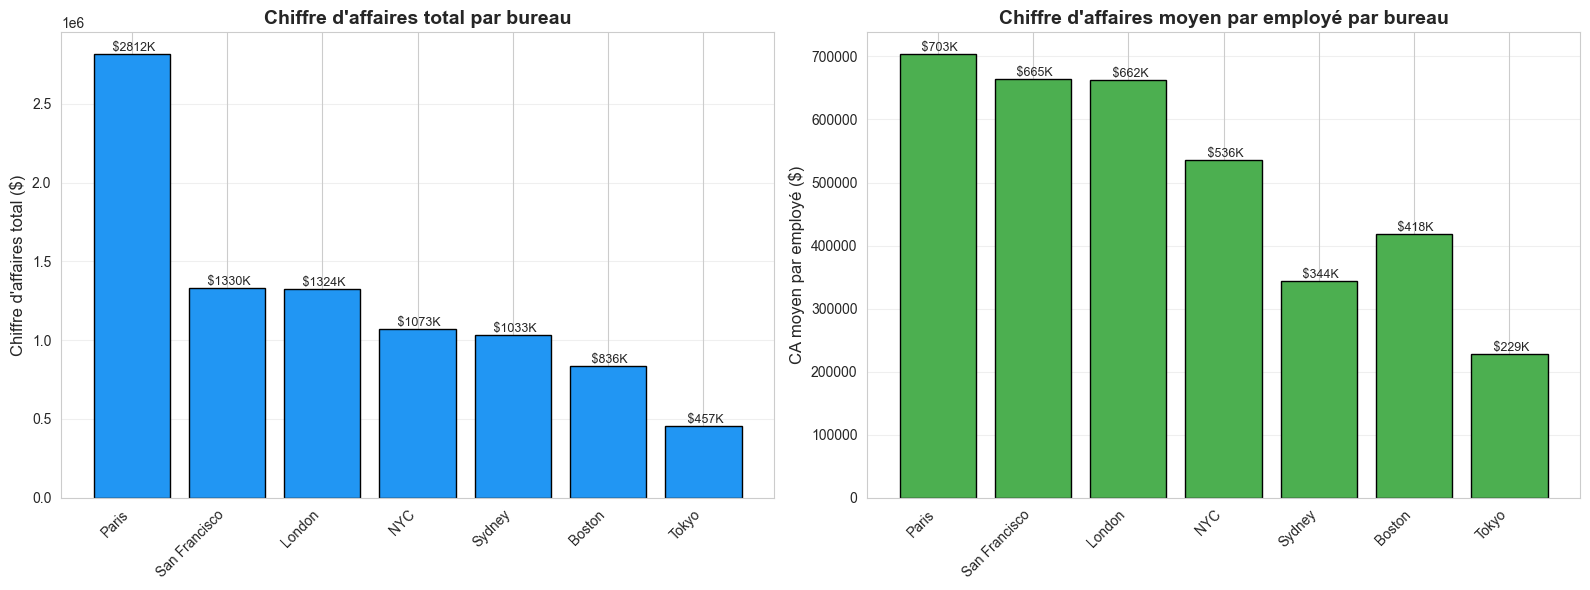

In [12]:
# Statistiques par bureau
office_stats = df_employee.groupby('office_city').agg({
    'chiffre_affaires': 'sum',
    'nb_clients': 'sum',
    'nb_commandes': 'sum',
    'employeeNumber': 'count'
}).reset_index()
office_stats.columns = ['bureau', 'CA_total', 'nb_clients_total', 'nb_commandes_total', 'nb_employes']

# Calculer le CA moyen par employé par bureau
office_stats['CA_moyen_par_employe'] = office_stats['CA_total'] / office_stats['nb_employes']
office_stats = office_stats.sort_values('CA_total', ascending=False)

print("=" * 100)
print("PERFORMANCES PAR BUREAU")
print("=" * 100)
display(office_stats)

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. CA total par bureau
axes[0].bar(range(len(office_stats)), office_stats['CA_total'], color='#2196F3', edgecolor='black')
axes[0].set_xticks(range(len(office_stats)))
axes[0].set_xticklabels(office_stats['bureau'], rotation=45, ha='right', fontsize=10)
axes[0].set_ylabel('Chiffre d\'affaires total ($)', fontsize=12)
axes[0].set_title('Chiffre d\'affaires total par bureau', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(office_stats.iterrows()):
    axes[0].text(i, row['CA_total'], f" ${row['CA_total']/1000:.0f}K", 
                ha='center', va='bottom', fontsize=9)

# 2. CA moyen par employé par bureau
axes[1].bar(range(len(office_stats)), office_stats['CA_moyen_par_employe'], color='#4CAF50', edgecolor='black')
axes[1].set_xticks(range(len(office_stats)))
axes[1].set_xticklabels(office_stats['bureau'], rotation=45, ha='right', fontsize=10)
axes[1].set_ylabel('CA moyen par employé ($)', fontsize=12)
axes[1].set_title('Chiffre d\'affaires moyen par employé par bureau', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for i, (idx, row) in enumerate(office_stats.iterrows()):
    axes[1].text(i, row['CA_moyen_par_employe'], f" ${row['CA_moyen_par_employe']/1000:.0f}K", 
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [8]:
# Identifier le meilleur employé dans chaque métrique
best_ca = df_employee.loc[df_employee['chiffre_affaires'].idxmax()]
best_clients = df_employee.loc[df_employee['nb_clients'].idxmax()]
df_with_panier = df_employee[df_employee['panier_moyen'] > 0]
if len(df_with_panier) > 0:
    best_panier = df_with_panier.loc[df_with_panier['panier_moyen'].idxmax()]
else:
    best_panier = None

# Créer un tableau récapitulatif
summary_data = {
    'Métrique': [
        'Meilleur CA',
        'Plus de clients gérés',
        'Meilleur panier moyen',
        'CA total de tous les employés',
        'Nombre moyen de clients par employé',
        'Bureau le plus performant (CA total)'
    ],
    'Employé / Valeur': [
        f"{best_ca['nom_complet']} (${best_ca['chiffre_affaires']:,.2f})",
        f"{best_clients['nom_complet']} ({int(best_clients['nb_clients'])} clients)",
        f"{best_panier['nom_complet']} (${best_panier['panier_moyen']:,.2f})" if best_panier is not None else "N/A",
        f"${df_employee['chiffre_affaires'].sum():,.2f}",
        f"{df_employee['nb_clients'].mean():.2f}",
        f"{office_stats.iloc[0]['bureau']} (${office_stats.iloc[0]['CA_total']:,.2f})"
    ]
}

summary_df = pd.DataFrame(summary_data)

print("=" * 100)
print("RÉSUMÉ DES PERFORMANCES EMPLOYÉS")
print("=" * 100)
display(summary_df)

RÉSUMÉ DES PERFORMANCES EMPLOYÉS


,Métrique,Employé / Valeur
0,Meilleur CA,"Gerard Hernandez ($1,065,035.29)"
1,Plus de clients gérés,Pamela Castillo (10 clients)
2,Meilleur panier moyen,"Martin Gerard ($42,709.79)"
3,CA total de tous les employés,"$8,865,094.64"
4,Nombre moyen de clients par employé,4.35
5,Bureau le plus performant (CA total),"Paris ($2,812,295.95)"
